# Forecasting the September 2022 California Heat Wave — SFNO vs Aurora (vs ERA5)

The **September 2022 California heat wave** was a record-breaking event (window ~Aug 31 – Sep 9 2022; peak ~Sep 6, when Sacramento hit 116 °F / 46.7 °C). This notebook asks how well two AI weather models foresaw it at a ~7-day lead: NVIDIA's **SFNO** (run through Makani) and Microsoft's **Aurora**. Both are driven by NVIDIA **Earth2Studio**'s `deterministic()` pipeline, initialized from the same **ERA5** state (fetched from the Copernicus Climate Data Store) at **2022-08-30 00Z** — the day before onset — and integrated for 12 days. Verification is against ERA5 **daily maximum 2 m temperature** from the Copernicus CDS, at **global, CONUS and California** scales. You will see peak-day maps with `model − ERA5` differences, heat-wave day counts, bias / RMSE / MAE by day, a consolidated skill table, and per-model city time series.

> **Measured on an NVIDIA L40:** 7 min runtime · 30.6 GiB peak GPU memory.

**Contents**
1. Model registry
2. Run the global forecasts (one per model)
3. Load forecasts, fetch ERA5, regrid Aurora, align
4. Helpers: regional cropping, longitude conversion, heat-wave metrics
5. Comparison grid — peak-day maps, all models vs ERA5 (5b: heat-wave day counts)
6. Cross-model skill — RMSE / bias vs lead, California (6b: consolidated skill table)
7. Per-model deep dives — model vs ERA5

The notebook ends with a **Summary** of what each figure and table answers.

**Design**
- **Models:** a single ~12-day global deterministic forecast per model, all initialized **2022-08-30 00Z** (the day before onset, ~7-day lead to the peak). Each model is driven through the same `deterministic()` pipeline via a small `MODELS` registry.
- **Comparison variable:** **2 m temperature (`t2m`)** only — the field every model emits. Analyzed at **three scales**: global, continental US (CONUS), and California.
- **Verification:** ERA5 `t2m` from the Copernicus CDS, for the same valid times.
- **Heat-wave metric:** absolute **daily-maximum 2 m temperature** thresholds (≥ 37.8 °C / 100 °F and ≥ 40 °C / 104 °F) sustained ≥ 3 consecutive days (§5b), plus per-model **bias / RMSE / MAE** vs ERA5 (§6, §6b).
- **Truth and sampling caveats:** ERA5 is a reanalysis — a model constrained by observations, not station data. Forecasts and ERA5 are both sampled every 6 hours (00, 06, 12, 18 UTC), so "daily maximum" means the largest of those four samples: slightly below the true daily peak, but identical for the models and ERA5.

**Per-model wrinkles (captured as registry flags; detail in §3).**
- **Aurora** runs on a 720×1440 grid (no south pole) vs the 721×1440 grid of SFNO / ERA5, so its output is regridded onto the ERA5 latitude grid before differencing (`regrid=True`).

**Visualization modes.**
1. **Comparison grid** (§5) — peak-day maps with every model + ERA5 side-by-side per region, plus `model − ERA5` difference panels. Use it to *rank* the models spatially.
2. **Per-model deep dive** (§7) — for each model, a grouped figure of city daily-Tmax time series (model vs ERA5) and the model's error growth (bias/RMSE/MAE vs lead), for investigating one model in isolation. A cross-model RMSE/bias overlay (§6) summarizes "which model captured the heat dome best".

In [1]:
# Environment: must be set before torch / earth2studio are imported.
import os

os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

import gc
import shutil
import warnings
from collections import OrderedDict
from pathlib import Path

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable
import numpy as np
import pandas as pd
import torch
import xarray as xr

from earth2studio.data import CDS
from earth2studio.io import ZarrBackend
from earth2studio.models.px import SFNO, Aurora
from earth2studio.run import deterministic
from earth2studio.utils.imports import OptionalDependencyError

warnings.filterwarnings("ignore")

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", DEVICE, "| torch", torch.__version__)


def free_gpu(*names: str) -> None:
    """Delete the named notebook variables (models, tensors), collect garbage, and release cached CUDA memory."""
    scope = globals()
    for name in names:
        scope.pop(name, None)
    gc.collect()
    torch.cuda.empty_cache()


def map_colorbar(fig, ax, mappable, label=None, orientation="vertical", **kwargs):
    '''Colorbar attached to `ax` that is exactly as long as the drawn map (never longer).

    fig.colorbar(..., ax=ax, shrink=...) sizes the bar from the axes box before a map's fixed
    aspect ratio is applied, so on wide maps the bar comes out taller than the map.'''
    side, pad = ("right", 0.1) if orientation == "vertical" else ("bottom", 0.35)
    cax = make_axes_locatable(ax).append_axes(side, size="4%", pad=pad, axes_class=plt.Axes)
    return fig.colorbar(mappable, cax=cax, orientation=orientation, label=label, **kwargs)


PROJECT = Path.cwd()  # JupyterLab and nbconvert both start in the notebook's folder
RESULTS_DIR = PROJECT / "docs" / "results"  # small CSV metric tables that the README embeds
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
DATA_DIR = PROJECT / "data"
FIG_DIR = PROJECT / "figures"
for d in (DATA_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

INIT_TIME     = np.datetime64("2022-08-30T00:00:00")  # day before onset; ~7-day lead to peak
FORECAST_DAYS = 12
NSTEPS        = FORECAST_DAYS * 4                     # 6-hourly steps
EVENT_START   = np.datetime64("2022-08-31")
EVENT_PEAK    = np.datetime64("2022-09-06")
EVENT_END     = np.datetime64("2022-09-09")
PRIMARY_VARS  = np.array(["t2m"])                       # the one field every model emits

MODELS = {
    "SFNO":   dict(cls=SFNO,   label="SFNO",    regrid=False, prefix="sfno",   extra="sfno"),
    "Aurora": dict(cls=Aurora, label="Aurora",  regrid=True,  prefix="aurora", extra="aurora"),
}

# Regions: lat=(min,max); lon given in BOTH 0-360 (SFNO/ERA5 native) and -180..180 (plotting).
REGIONS = {
    "GLOBAL":     dict(lat=(-90, 90), lon360=(0, 360),   lon180=(-180, 180)),
    "CONUS":      dict(lat=(24, 50),  lon360=(235, 294), lon180=(-125, -66)),
    "CALIFORNIA": dict(lat=(32, 42),  lon360=(235, 246), lon180=(-125, -114)),
}

# Cities: name -> (lat, lon in -180..180)
CITIES = {
    "Sacramento":   (38.58, -121.49),
    "Fresno":       (36.74, -119.79),
    "Los Angeles":  (34.05, -118.24),
    "Death Valley": (36.46, -116.87),
    "Phoenix":      (33.45, -112.07),
    "Las Vegas":    (36.17, -115.14),
}

# Absolute daily-Tmax thresholds (deg C)
THRESHOLDS_C      = {"hot (100F)": 37.8, "extreme (104F)": 40.0}
HEATWAVE_MIN_DAYS = 3

print(f"init {INIT_TIME}  |  {NSTEPS} steps x 6h = {FORECAST_DAYS} days")
print("models:", ", ".join(f"{k} ({v['label']})" for k, v in MODELS.items()))

device: cuda | torch 2.13.0+cu132
init 2022-08-30T00:00:00  |  48 steps x 6h = 12 days
models: SFNO (SFNO), Aurora (Aurora)


## 1 · Model registry

Two models, both initialized from ERA5 — no lexicon patching needed since SFNO and Aurora resolve
entirely from earth2studio's stock CDS lexicon. Model weights are loaded lazily inside
`run_forecast()` (only on a cache miss), so this cell stays cheap.

In [2]:
print("Models to compare:")
for k, s in MODELS.items():
    print(f"  {k:7s} {s['label']:9s}  regrid={s['regrid']!s:5s}  prefix={s['prefix']}")

Models to compare:
  SFNO    SFNO       regrid=False  prefix=sfno
  Aurora  Aurora     regrid=True   prefix=aurora


## 2 · Run the global forecasts (one per model)

`run_forecast(key, init_time)` drives any model in the registry through the identical earth2studio
`deterministic()` pipeline: it initializes from ERA5 (each model auto-fetches the input snapshots its
`input_coords()` requires — e.g. Aurora uses a two-step `[-6h, 0h]` init) and integrates
`NSTEPS` 6-hour steps, saving `t2m` to a per-model Zarr store. To bound GPU memory, the model weights
are **loaded only on a cache miss and freed immediately after** — so at most one model is resident at a
time. The **first** SFNO / Aurora run downloads
the checkpoint and the full ERA5 initial state from CDS (slow, then cached); Aurora is the heavy one.
Any model whose optional dependencies are missing is skipped (with a warning) rather than failing the
whole run. Each store is written to `<name>.zarr.partial` and renamed only when the run completes, so a
killed kernel never leaves a finished-looking store behind; the file name carries the variables and the
number of steps, so changing either one never reuses a stale forecast.

In [3]:
def run_forecast(key, init_time, nsteps=NSTEPS, variables=PRIMARY_VARS, overwrite=False):
    '''Deterministic global forecast for model `key` from an ERA5 init -> path to a Zarr store.

    The model weights are loaded only on a cache miss and freed afterwards, so at most one model
    is resident on the GPU at a time (Aurora is large).'''
    spec = MODELS[key]
    tag      = np.datetime_as_string(np.datetime64(init_time), unit="D").replace("-", "")
    vtag     = "-".join(str(v) for v in variables)
    out_path = DATA_DIR / f"{spec['prefix']}_forecast_init{tag}_{vtag}_{nsteps}steps.zarr"
    if out_path.exists() and not overwrite:
        print(f"{key:7s} using cached forecast: {out_path.name}")
        return out_path
    # ZarrBackend allocates the whole lead axis up front, so a store left by a killed kernel looks complete.
    # Write to <name>.partial and rename it only after the run finishes; the cache check above sees only <name>.
    partial = out_path.with_name(out_path.name + ".partial")
    shutil.rmtree(partial, ignore_errors=True)       # stale partial store from an interrupted run
    print(f"{key:7s} loading model + running {nsteps} steps ...")
    model = None
    try:
        model = spec["cls"].load_model(spec["cls"].load_default_package()).to(DEVICE)
        deterministic(
            time=[np.datetime64(init_time)],
            nsteps=nsteps,
            prognostic=model,
            data=CDS(cache=True),
            io=ZarrBackend(str(partial), backend_kwargs={"overwrite": True}),
            output_coords=OrderedDict({"variable": np.asarray(variables)}),
            device=DEVICE,
        )
    except BaseException:
        shutil.rmtree(partial, ignore_errors=True)   # never leave a half-written store behind
        raise
    finally:
        # `model` is a local, so free_gpu cannot pop it by name: drop the last reference here,
        # then collect garbage and release cached CUDA memory. After a failed run the traceback can
        # still keep the model alive, so restart the kernel after an error.
        model = None
        free_gpu()
    shutil.rmtree(out_path, ignore_errors=True)      # overwrite=True: replace the old finished store
    partial.rename(out_path)
    print(f"{key:7s} forecast -> {out_path.name}")
    return out_path

# Missing optional dependencies -> skip the model instead of crashing. Other errors (a real bug
# mid-run) are not caught, so they cannot silently drop a model from the results.
LOAD_DEP_ERRORS = (OptionalDependencyError, ImportError)

# Run each model; skip (and drop from MODELS) any whose optional dependencies are missing.
paths, _skipped = {}, []
for k in list(MODELS):
    try:
        paths[k] = run_forecast(k, INIT_TIME)
    except LOAD_DEP_ERRORS as e:
        _skipped.append(k)
        print(f"{k:7s} SKIPPED ({type(e).__name__}) — needs earth2studio[{MODELS[k]['extra']}] with a "
              f"working dependency stack. First line: {str(e).splitlines()[0][:120]}")
for k in _skipped:
    del MODELS[k]

print("\nactive models:", list(MODELS))
print("forecast Zarr stores:")
for k, p in paths.items():
    print(f"  {k:7s} {p}")

SFNO    loading model + running 48 steps ...


2026-11-01 04:53:24.622 | INFO     | earth2studio.run:deterministic:85 - Running simple workflow!
2026-11-01 04:53:24.622 | INFO     | earth2studio.run:deterministic:92 - Inference device: cuda
2026-11-01 04:53:24.649 | DEBUG    | earth2studio.data.cds:_fetch_process:202 - Fetching CDS grib file for variable: 10m_u_component_of_wind at 2022-08-30 00:00:00 with 1 levels
2026-11-01 04:53:24.649 | DEBUG    | earth2studio.data.cds:_fetch_process:202 - Fetching CDS grib file for variable: 10m_v_component_of_wind at 2022-08-30 00:00:00 with 1 levels
2026-11-01 04:53:24.649 | DEBUG    | earth2studio.data.cds:_fetch_process:202 - Fetching CDS grib file for variable: 100m_u_component_of_wind at 2022-08-30 00:00:00 with 1 levels
2026-11-01 04:53:24.649 | DEBUG    | earth2studio.data.cds:_fetch_process:202 - Fetching CDS grib file for variable: 100m_v_component_of_wind at 2022-08-30 00:00:00 with 1 levels
2026-11-01 04:53:24.649 | DEBUG    | earth2studio.data.cds:_fetch_process:202 - Fetching CDS

2026-11-01 04:53:26.785 | SUCCESS  | earth2studio.run:deterministic:154 - Fetched data from CDS
2026-11-01 04:53:26.787 | INFO     | earth2studio.run:deterministic:162 - Inference starting!


2026-11-01 04:53:45.706 | SUCCESS  | earth2studio.run:deterministic:189 - 
Inference complete


SFNO    forecast -> sfno_forecast_init20220830_t2m_48steps.zarr
Aurora  loading model + running 48 steps ...


2026-11-01 04:54:04.423 | INFO     | earth2studio.run:deterministic:85 - Running simple workflow!
2026-11-01 04:54:04.423 | INFO     | earth2studio.run:deterministic:92 - Inference device: cuda
2026-11-01 04:54:04.446 | DEBUG    | earth2studio.data.cds:_fetch_process:202 - Fetching CDS grib file for variable: geopotential at 2022-08-29 18:00:00 with 13 levels
2026-11-01 04:54:04.446 | DEBUG    | earth2studio.data.cds:_fetch_process:202 - Fetching CDS grib file for variable: specific_humidity at 2022-08-29 18:00:00 with 13 levels
2026-11-01 04:54:04.446 | DEBUG    | earth2studio.data.cds:_fetch_process:202 - Fetching CDS grib file for variable: temperature at 2022-08-29 18:00:00 with 13 levels
2026-11-01 04:54:04.446 | DEBUG    | earth2studio.data.cds:_fetch_process:202 - Fetching CDS grib file for variable: u_component_of_wind at 2022-08-29 18:00:00 with 13 levels
2026-11-01 04:54:04.446 | DEBUG    | earth2studio.data.cds:_fetch_process:202 - Fetching CDS grib file for variable: v_comp

2026-11-01 04:54:05.967 | DEBUG    | earth2studio.data.cds:_fetch_process:202 - Fetching CDS grib file for variable: geopotential at 2022-08-30 00:00:00 with 13 levels
2026-11-01 04:54:05.968 | DEBUG    | earth2studio.data.cds:_fetch_process:202 - Fetching CDS grib file for variable: specific_humidity at 2022-08-30 00:00:00 with 13 levels
2026-11-01 04:54:05.968 | DEBUG    | earth2studio.data.cds:_fetch_process:202 - Fetching CDS grib file for variable: temperature at 2022-08-30 00:00:00 with 13 levels
2026-11-01 04:54:05.969 | DEBUG    | earth2studio.data.cds:_fetch_process:202 - Fetching CDS grib file for variable: u_component_of_wind at 2022-08-30 00:00:00 with 13 levels
2026-11-01 04:54:05.969 | DEBUG    | earth2studio.data.cds:_fetch_process:202 - Fetching CDS grib file for variable: v_component_of_wind at 2022-08-30 00:00:00 with 13 levels
2026-11-01 04:54:05.969 | DEBUG    | earth2studio.data.cds:_fetch_process:202 - Fetching CDS grib file for variable: mean_sea_level_pressure a

2026-11-01 04:54:07.732 | SUCCESS  | earth2studio.run:deterministic:154 - Fetched data from CDS
2026-11-01 04:54:07.734 | INFO     | earth2studio.run:deterministic:162 - Inference starting!


2026-11-01 04:58:42.072 | SUCCESS  | earth2studio.run:deterministic:189 - 
Inference complete


Aurora  forecast -> aurora_forecast_init20220830_t2m_48steps.zarr

active models: ['SFNO', 'Aurora']
forecast Zarr stores:
  SFNO    /home/jovyan/West-Coast/data/sfno_forecast_init20220830_t2m_48steps.zarr
  Aurora  /home/jovyan/West-Coast/data/aurora_forecast_init20220830_t2m_48steps.zarr


## 3 · Load forecasts, fetch ERA5, regrid Aurora, align

For each model we read its `t2m`, attach a **valid-time** axis (`init + lead`), and convert to °C. We
fetch ERA5 `t2m` once at those valid times (it shares the SFNO 0.25° 721×1440 grid). **Aurora**
lives on a 720×1440 grid (no south pole), so its field is interpolated onto the ERA5 latitude grid
(`regrid=True`) before comparison — see `load_forecast_t2m()` below for the interpolation detail; the
boundary effect at the pole is immaterial for a California heat-wave. Finally every model and ERA5 are
aligned on the common valid-time axis. All series are sampled 6-hourly, so the daily-Tmax comparison is
apples-to-apples across models.

In [4]:
def load_forecast_t2m(path, init_time, regrid_to=None):
    '''Open a forecast Zarr -> t2m DataArray (valid_time, lat, lon) in deg C.

    If `regrid_to` (a DataArray carrying lat/lon coords) is given, interpolate onto its grid.
    Used for Aurora's 720x1440 grid -> the ERA5/SFNO 721x1440 grid (1-D lat interp; lon is identical).'''
    ds = xr.open_zarr(str(path))
    da = ds["t2m"]
    for d in ("batch", "time"):                       # squeeze singleton init dims
        if d in da.dims:
            da = da.isel({d: 0}, drop=True)
    valid = np.datetime64(init_time) + da["lead_time"].values
    da = da.assign_coords(lead_time=valid).rename(lead_time="valid_time")
    da = (da - 273.15).assign_attrs(units="degC")
    if regrid_to is not None:
        da = da.interp(lon=regrid_to["lon"])                                   # identical grid in practice
        da = da.interp(lat=regrid_to["lat"], kwargs={"fill_value": "extrapolate"})  # 720 -> 721, fill pole
    return da

def fetch_era5_t2m(times):
    '''ERA5 t2m at the given valid times via earth2studio's CDS data source
    -> DataArray (valid_time, lat, lon) in deg C. Same backend as the model init
    (idiomatic, self-caching) and grid-matched (721x1440) to the forecasts.'''
    src = CDS(cache=True)
    da = src(time=np.asarray(times), variable="t2m")     # (time, variable, lat, lon), Kelvin
    da = da.isel(variable=0, drop=True).rename(time="valid_time")
    return (da - 273.15).assign_attrs(units="degC")

# Valid times come from any model (all share init + steps).
REF_KEY     = next(iter(paths))
valid_times = load_forecast_t2m(paths[REF_KEY], INIT_TIME)["valid_time"].values
era5_t2m    = fetch_era5_t2m(valid_times)

# Load every model's t2m (regridding onto the ERA5 grid where flagged).
fc = {k: load_forecast_t2m(paths[k], INIT_TIME,
                           regrid_to=(era5_t2m if MODELS[k]["regrid"] else None))
      for k in MODELS}

# Align all models + ERA5 on the common (valid_time, lat, lon) axes.
aligned = xr.align(*fc.values(), era5_t2m, join="inner")
fc = {k: aligned[i] for i, k in enumerate(fc)}
era5_t2m = aligned[-1]

print("aligned grid:", dict(era5_t2m.sizes), "|", str(era5_t2m["valid_time"].values[0])[:13],
      "->", str(era5_t2m["valid_time"].values[-1])[:13])
for k in fc:
    print(f"  {k:7s} {MODELS[k]['label']:9s} {dict(fc[k].sizes)}  NaNs={bool(np.isnan(fc[k].values).any())}")
print("  ERA5    truth      ", dict(era5_t2m.sizes), " NaNs=", bool(np.isnan(era5_t2m.values).any()))

2026-11-01 04:58:43.381 | DEBUG    | earth2studio.data.cds:_fetch_process:202 - Fetching CDS grib file for variable: 2m_temperature at 2022-08-30 00:00:00 with 1 levels
2026-11-01 04:58:43.404 | DEBUG    | earth2studio.data.cds:_fetch_process:202 - Fetching CDS grib file for variable: 2m_temperature at 2022-08-30 06:00:00 with 1 levels
2026-11-01 04:58:43.426 | DEBUG    | earth2studio.data.cds:_fetch_process:202 - Fetching CDS grib file for variable: 2m_temperature at 2022-08-30 12:00:00 with 1 levels
2026-11-01 04:58:43.448 | DEBUG    | earth2studio.data.cds:_fetch_process:202 - Fetching CDS grib file for variable: 2m_temperature at 2022-08-30 18:00:00 with 1 levels
2026-11-01 04:58:43.469 | DEBUG    | earth2studio.data.cds:_fetch_process:202 - Fetching CDS grib file for variable: 2m_temperature at 2022-08-31 00:00:00 with 1 levels
2026-11-01 04:58:43.491 | DEBUG    | earth2studio.data.cds:_fetch_process:202 - Fetching CDS grib file for variable: 2m_temperature at 2022-08-31 06:00:00 

2026-11-01 04:58:43.555 | DEBUG    | earth2studio.data.cds:_fetch_process:202 - Fetching CDS grib file for variable: 2m_temperature at 2022-09-01 00:00:00 with 1 levels
2026-11-01 04:58:43.576 | DEBUG    | earth2studio.data.cds:_fetch_process:202 - Fetching CDS grib file for variable: 2m_temperature at 2022-09-01 06:00:00 with 1 levels


2026-11-01 04:58:43.598 | DEBUG    | earth2studio.data.cds:_fetch_process:202 - Fetching CDS grib file for variable: 2m_temperature at 2022-09-01 12:00:00 with 1 levels
2026-11-01 04:58:43.620 | DEBUG    | earth2studio.data.cds:_fetch_process:202 - Fetching CDS grib file for variable: 2m_temperature at 2022-09-01 18:00:00 with 1 levels
2026-11-01 04:58:43.641 | DEBUG    | earth2studio.data.cds:_fetch_process:202 - Fetching CDS grib file for variable: 2m_temperature at 2022-09-02 00:00:00 with 1 levels
2026-11-01 04:58:43.662 | DEBUG    | earth2studio.data.cds:_fetch_process:202 - Fetching CDS grib file for variable: 2m_temperature at 2022-09-02 06:00:00 with 1 levels
2026-11-01 04:58:43.684 | DEBUG    | earth2studio.data.cds:_fetch_process:202 - Fetching CDS grib file for variable: 2m_temperature at 2022-09-02 12:00:00 with 1 levels
2026-11-01 04:58:43.706 | DEBUG    | earth2studio.data.cds:_fetch_process:202 - Fetching CDS grib file for variable: 2m_temperature at 2022-09-02 18:00:00 

2026-11-01 04:58:43.775 | DEBUG    | earth2studio.data.cds:_fetch_process:202 - Fetching CDS grib file for variable: 2m_temperature at 2022-09-03 12:00:00 with 1 levels
2026-11-01 04:58:43.797 | DEBUG    | earth2studio.data.cds:_fetch_process:202 - Fetching CDS grib file for variable: 2m_temperature at 2022-09-03 18:00:00 with 1 levels


2026-11-01 04:58:43.820 | DEBUG    | earth2studio.data.cds:_fetch_process:202 - Fetching CDS grib file for variable: 2m_temperature at 2022-09-04 00:00:00 with 1 levels
2026-11-01 04:58:43.843 | DEBUG    | earth2studio.data.cds:_fetch_process:202 - Fetching CDS grib file for variable: 2m_temperature at 2022-09-04 06:00:00 with 1 levels
2026-11-01 04:58:43.866 | DEBUG    | earth2studio.data.cds:_fetch_process:202 - Fetching CDS grib file for variable: 2m_temperature at 2022-09-04 12:00:00 with 1 levels
2026-11-01 04:58:43.888 | DEBUG    | earth2studio.data.cds:_fetch_process:202 - Fetching CDS grib file for variable: 2m_temperature at 2022-09-04 18:00:00 with 1 levels
2026-11-01 04:58:43.911 | DEBUG    | earth2studio.data.cds:_fetch_process:202 - Fetching CDS grib file for variable: 2m_temperature at 2022-09-05 00:00:00 with 1 levels
2026-11-01 04:58:43.934 | DEBUG    | earth2studio.data.cds:_fetch_process:202 - Fetching CDS grib file for variable: 2m_temperature at 2022-09-05 06:00:00 

2026-11-01 04:58:43.979 | DEBUG    | earth2studio.data.cds:_fetch_process:202 - Fetching CDS grib file for variable: 2m_temperature at 2022-09-05 18:00:00 with 1 levels
2026-11-01 04:58:44.002 | DEBUG    | earth2studio.data.cds:_fetch_process:202 - Fetching CDS grib file for variable: 2m_temperature at 2022-09-06 00:00:00 with 1 levels


... (4 outputs left out)

2026-11-01 04:58:44.434 | DEBUG    | earth2studio.data.cds:_fetch_process:202 - Fetching CDS grib file for variable: 2m_temperature at 2022-09-10 18:00:00 with 1 levels
2026-11-01 04:58:44.458 | DEBUG    | earth2studio.data.cds:_fetch_process:202 - Fetching CDS grib file for variable: 2m_temperature at 2022-09-11 00:00:00 with 1 levels


aligned grid: {'valid_time': 49, 'lat': 721, 'lon': 1440} | 2022-08-30T00 -> 2022-09-11T00


  SFNO    SFNO      {'valid_time': 49, 'lat': 721, 'lon': 1440}  NaNs=False


  Aurora  Aurora    {'valid_time': 49, 'lat': 721, 'lon': 1440}  NaNs=False
  ERA5    truth       {'valid_time': 49, 'lat': 721, 'lon': 1440}  NaNs= False


## 4 · Helpers: regional cropping, longitude conversion, heat-wave metrics

Every comparison needs the same few operations — cut a region out of the global grid, put longitudes in the range cartopy expects, take daily maxima, and score a field against ERA5 with latitude weighting (grid cells shrink toward the poles, so they should count less) — so they live in one place and are reused by all the figures below.

In [5]:
def crop_bbox(da, lat_range, lon360_range, lat_name="lat", lon_name="lon"):
    '''Slice a DataArray (lon in 0-360, lat descending) to a bbox given in 0-360 lon.'''
    lo_lat, hi_lat = min(lat_range), max(lat_range)
    da = da.sel({lat_name: slice(hi_lat, lo_lat)})         # lat is descending
    lo_lon, hi_lon = lon360_range
    if lo_lon <= hi_lon:
        return da.sel({lon_name: slice(lo_lon, hi_lon)})
    lon = da[lon_name]
    return da.sel({lon_name: lon[(lon >= lo_lon) | (lon <= hi_lon)]})   # dateline wrap

def to_180(da, lon_name="lon"):
    '''Convert lon 0-360 -> -180..180 and sort (for cartopy plotting).'''
    da = da.assign_coords({lon_name: (((da[lon_name] + 180) % 360) - 180)})
    return da.sortby(lon_name)

def daily_tmax(da, time_name="valid_time", samples_per_day=4):
    '''6-hourly t2m -> daily maximum; renames the day axis to 'day'.

    A day with fewer than four 6-hourly samples (the last forecast time is a lone 00Z) is dropped:
    its maximum would come from one sample and would not be a daily maximum.'''
    n = da[time_name].to_series().resample("1D").count()      # samples per day
    out = da.resample({time_name: "1D"}).max().sel({time_name: n[n >= samples_per_day].index})
    return out.rename({time_name: "day"})

def area_weights(da, lat_name="lat"):
    '''cos(latitude) weights for a DataArray: grid cells shrink toward the poles, so they count less.'''
    w = np.cos(np.deg2rad(da[lat_name]))
    return w.where(np.isfinite(w), 0.0)

def exceedance_mask(tmax_daily, thresh_c):
    '''Boolean field: True where the daily Tmax reaches the threshold (deg C).'''
    return tmax_daily >= thresh_c

def heatwave_daycount(mask, day_name="day", min_days=HEATWAVE_MIN_DAYS):
    '''Per gridpoint: number of days belonging to a run of >= min_days exceedance days.'''
    a = mask.transpose(day_name, ...)
    arr = a.values.astype(np.int32)
    D = arr.shape[0]
    # Run length at each day = (consecutive exceedance days ending here) + (starting here) - 1,
    # computed via one forward and one backward cumulative pass instead of a per-gridpoint loop.
    f = np.zeros_like(arr); b = np.zeros_like(arr)
    f[0] = arr[0]
    for d in range(1, D):  f[d] = arr[d] * (f[d - 1] + 1)
    b[-1] = arr[-1]
    for d in range(D - 2, -1, -1):  b[d] = arr[d] * (b[d + 1] + 1)
    runlen = np.where(arr > 0, f + b - 1, 0)
    daycount = (runlen >= min_days).sum(axis=0)
    dims = a.dims[1:]
    return xr.DataArray(daycount, dims=dims, coords={d: a.coords[d] for d in dims})

def error_metrics_per_day(model_daily, era5_daily, lat_name="lat"):
    '''cos(lat)-weighted bias / RMSE / MAE between a model daily-Tmax field and ERA5, per day.'''
    w = area_weights(model_daily, lat_name)
    diff = model_daily - era5_daily
    norm = (w * xr.ones_like(diff)).sum(("lat", "lon"))
    bias = (diff * w).sum(("lat", "lon")) / norm
    rmse = np.sqrt(((diff**2) * w).sum(("lat", "lon")) / norm)
    mae  = (np.abs(diff) * w).sum(("lat", "lon")) / norm
    return xr.Dataset({"bias": bias, "rmse": rmse, "mae": mae})

# Daily-Tmax fields used throughout: one per model + ERA5 truth.
tmax      = {k: daily_tmax(fc[k]) for k in MODELS}
era5_tmax = daily_tmax(era5_t2m)
days      = era5_tmax["day"].values
xdays     = pd.to_datetime(days)
xpeak     = pd.to_datetime(EVENT_PEAK)     # peak-day marker on the date axes (Sep 6)
print("daily Tmax days:", [str(d)[:10] for d in days])
print("models:", list(tmax))

daily Tmax days: ['2022-08-30', '2022-08-31', '2022-09-01', '2022-09-02', '2022-09-03', '2022-09-04', '2022-09-05', '2022-09-06', '2022-09-07', '2022-09-08', '2022-09-09', '2022-09-10']
models: ['SFNO', 'Aurora']


## 5 · Comparison grid — peak-day maps, all models vs ERA5

Peak-day 2 m daily-Tmax at each scale. **Top row:** every model + ERA5 truth on a shared color scale.
**Bottom row:** each `model − ERA5` difference on a shared symmetric scale (the ERA5 column has no diff).
These are ~7-day-lead forecasts, so meaningful differences are expected — this view ranks the models
spatially at a glance.

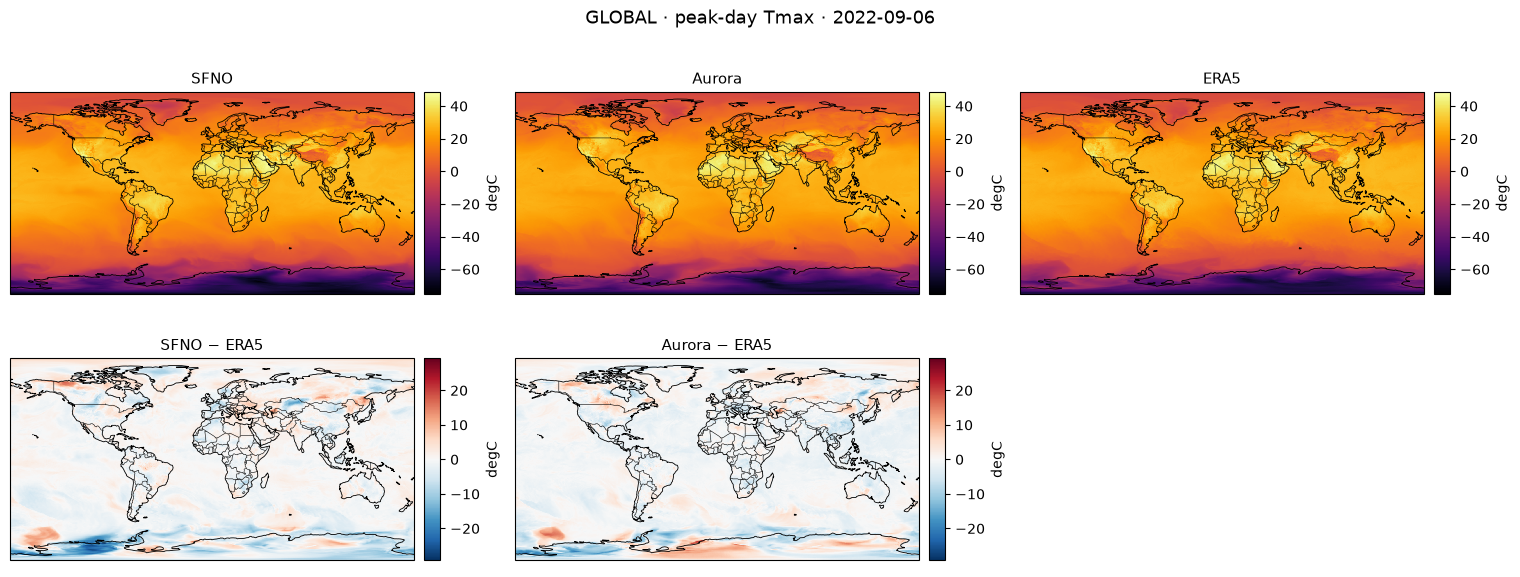

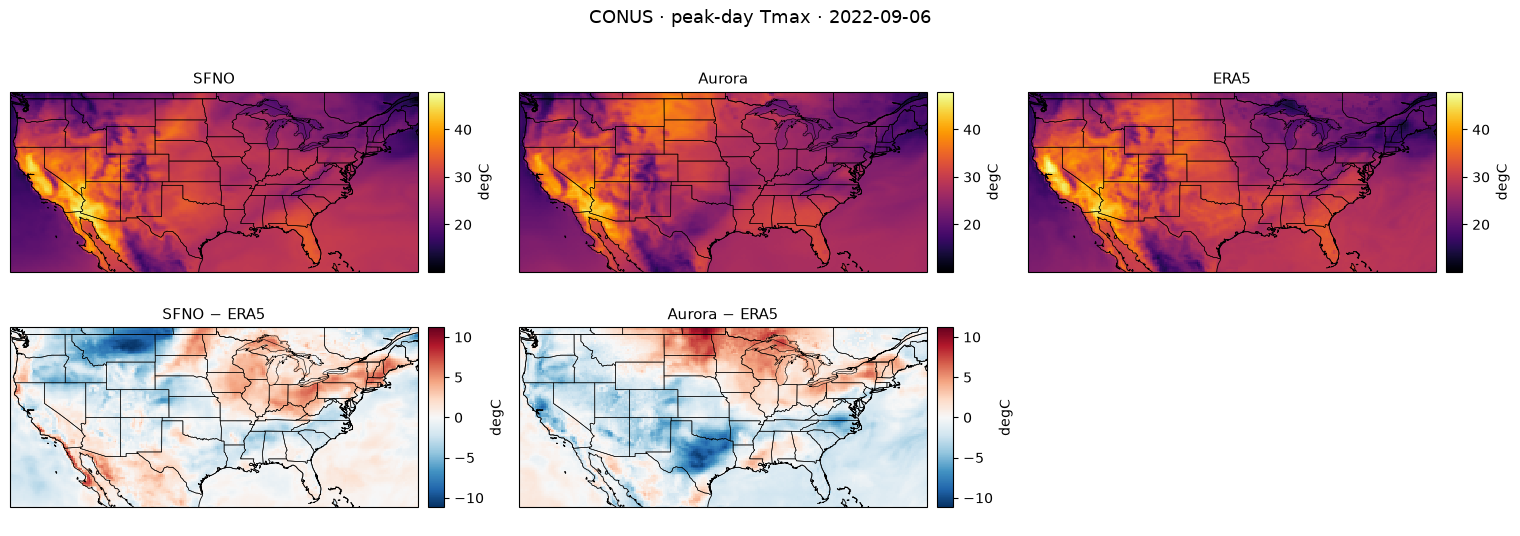

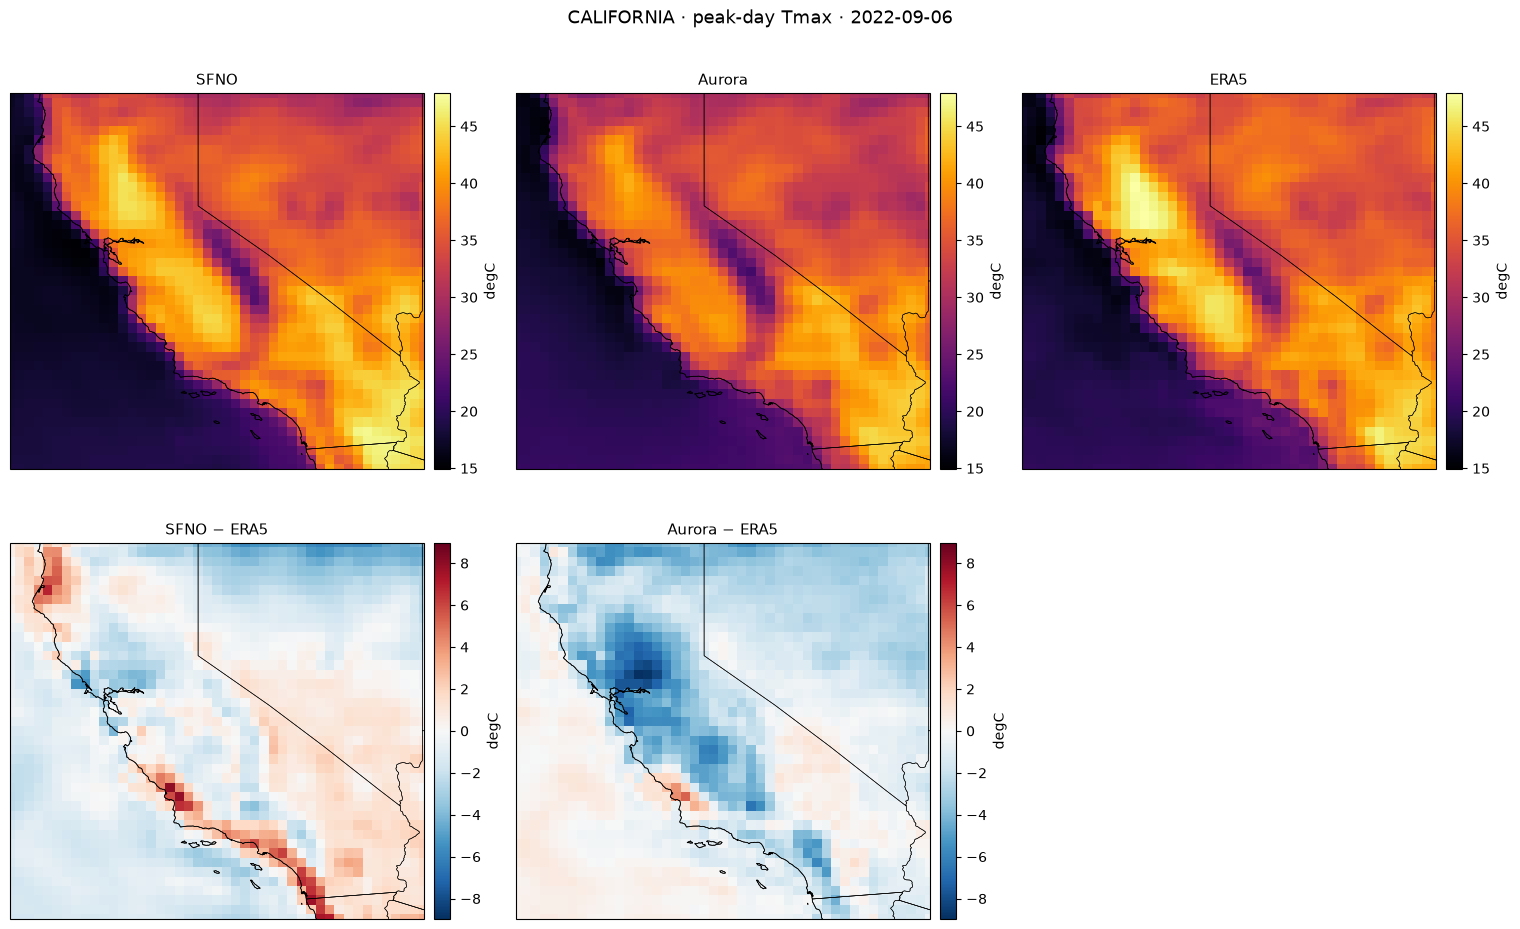

In [6]:
def comparison_grid(region):
    '''Peak-day Tmax maps: top row = each model + ERA5; bottom row = model - ERA5 differences.'''
    info = REGIONS[region]
    peak = days[np.argmin(np.abs(days - EVENT_PEAK))]

    # crop+convert once per model; ERA5 too
    e = to_180(crop_bbox(era5_tmax.sel(day=peak), info["lat"], info["lon360"]))
    mflds = {MODELS[k]["label"]: to_180(crop_bbox(tmax[k].sel(day=peak), info["lat"], info["lon360"]))
             for k in MODELS}
    top   = {**mflds, "ERA5": e}
    diffs = {lab: fld - e for lab, fld in mflds.items()}

    vmin = float(min(f.min() for f in top.values()))
    vmax = float(max(f.max() for f in top.values()))
    dmax = max(float(np.nanmax(np.abs(d.values))) for d in diffs.values()) or 1.0

    ncol = len(top)                                   # models + ERA5
    # Size each row to the map's own shape: a wide region (world, CONUS) needs a short row.
    shape = abs(info["lat"][1] - info["lat"][0]) / abs(info["lon180"][1] - info["lon180"][0])
    row_h = 4.4 * shape + 0.8                         # map height at 4.4 in wide, plus title room
    fig, axes = plt.subplots(2, ncol, figsize=(5.1 * ncol, 2 * row_h),
                             subplot_kw={"projection": ccrs.PlateCarree()})

    def style(ax):
        ax.set_extent([*info["lon180"], *info["lat"]], crs=ccrs.PlateCarree())
        ax.add_feature(cfeature.COASTLINE, lw=0.6)
        ax.add_feature(cfeature.BORDERS, lw=0.4)
        if region != "GLOBAL":
            ax.add_feature(cfeature.STATES, lw=0.4)

    for ax, (name, fld) in zip(axes[0], top.items()):
        m = ax.pcolormesh(fld["lon"], fld["lat"], fld, cmap="inferno", vmin=vmin, vmax=vmax,
                          shading="auto", transform=ccrs.PlateCarree())
        style(ax)
        ax.set_title(name, fontsize=11)
        map_colorbar(fig, ax, m, label="degC")

    # ERA5 column has no diff, left blank
    for ax, (name, d) in zip(axes[1], diffs.items()):
        m = ax.pcolormesh(d["lon"], d["lat"], d, cmap="RdBu_r", vmin=-dmax, vmax=dmax,
                          shading="auto", transform=ccrs.PlateCarree())
        style(ax)
        ax.set_title(f"{name} − ERA5", fontsize=11)
        map_colorbar(fig, ax, m, label="degC")
    for ax in axes[1][len(diffs):]:
        ax.axis("off")

    fig.suptitle(f"{region} · peak-day Tmax · {str(peak)[:10]}", y=1.0, fontsize=13)
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"maps_peakday_{region.lower()}.png", dpi=110, bbox_inches="tight")
    plt.show()

for r in ("GLOBAL", "CONUS", "CALIFORNIA"):
    comparison_grid(r)

**How to read this.** Each figure covers one region. The top row shows the peak-day daily-maximum 2 m temperature (°C) for every model and for ERA5 on one shared color scale, so equal colors mean equal temperatures. The bottom row shows `model − ERA5` on a symmetric scale: red means the model is too hot, blue too cool, and white means close agreement. Look for whether each model puts the hottest air (the Central Valley and the desert Southwest) where ERA5 does, and whether its errors are a broad offset or concentrated in particular areas.

## 5b · Heat-wave day counts

A heat wave is about persistence, not a single hot afternoon. For each grid cell this section counts how many days of the event window (Aug 31 – Sep 9) belong to a run of at least three consecutive days with daily maximum temperature at or above a threshold: 37.8 °C (100 °F, top row) and 40 °C (104 °F, bottom row). ERA5 is the reference.

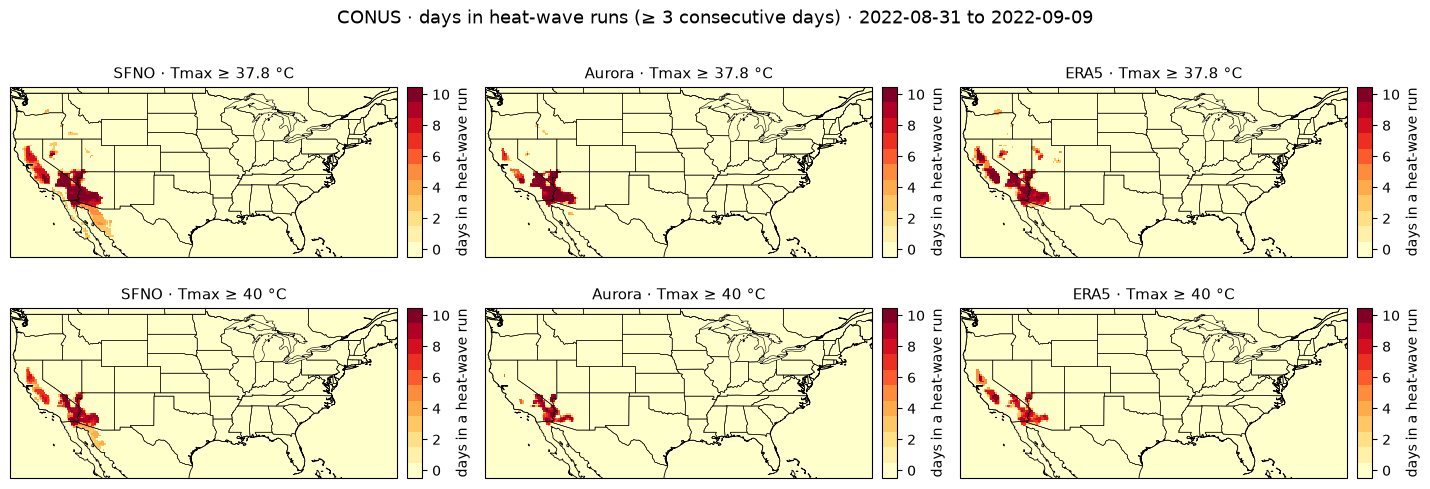

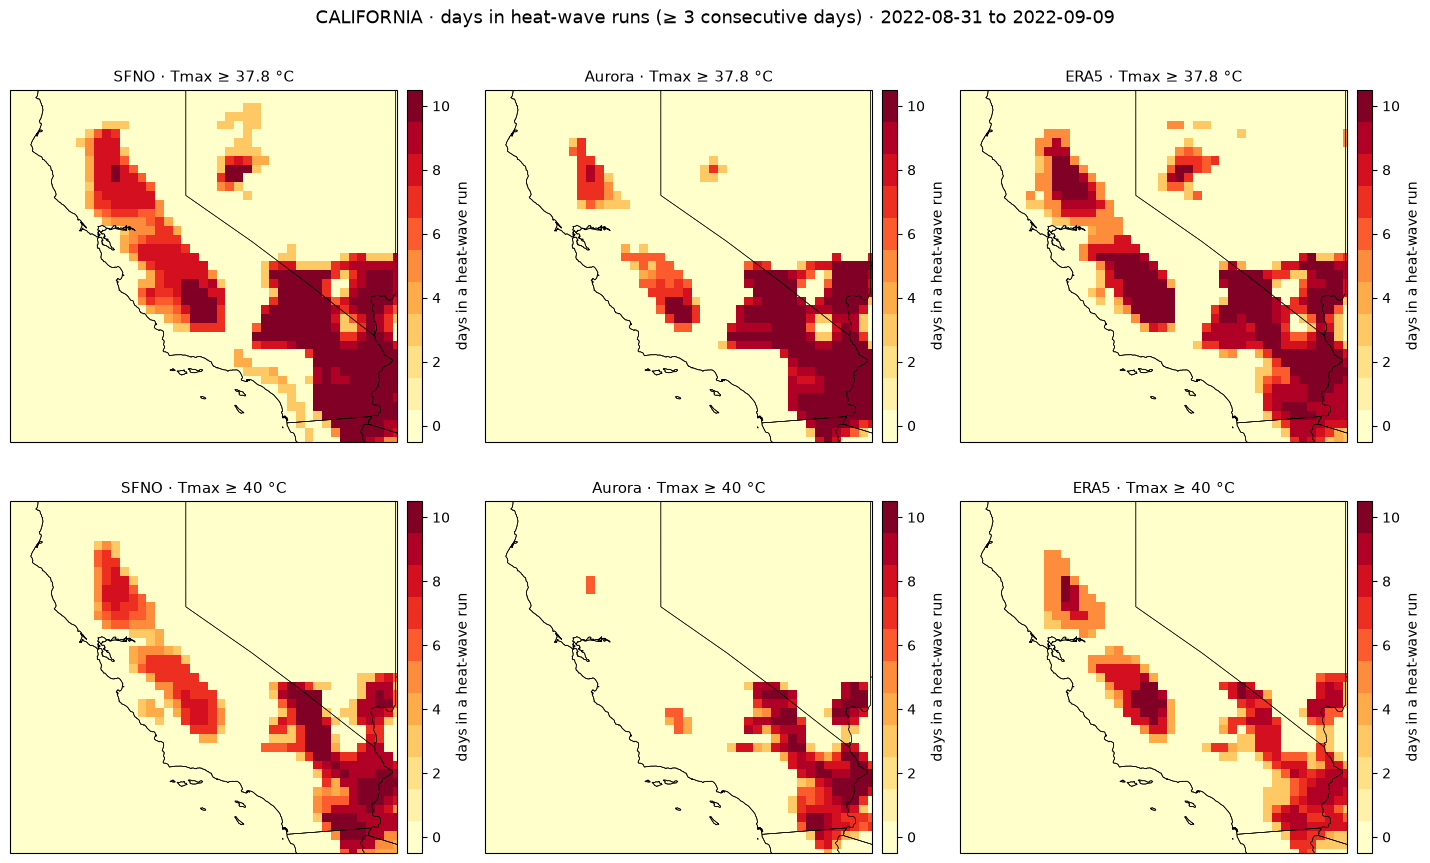

In [7]:
def daycount_grid(region):
    '''Heat-wave day-count maps: one row per threshold in THRESHOLDS_C, one column per model plus ERA5.

    A cell scores one for every event-window day that belongs to a run of at least
    HEATWAVE_MIN_DAYS consecutive days at or above the threshold.'''
    info = REGIONS[region]
    window = slice(EVENT_START, EVENT_END)
    n_days = int(era5_tmax.sel(day=window).sizes["day"])
    fields = {MODELS[k]["label"]: tmax[k] for k in MODELS}
    fields["ERA5"] = era5_tmax

    shape = abs(info["lat"][1] - info["lat"][0]) / abs(info["lon180"][1] - info["lon180"][0])
    row_h = 4.0 * shape + 0.8                         # map height at 4.0 in wide, plus title room
    fig, axes = plt.subplots(len(THRESHOLDS_C), len(fields),
                             figsize=(4.8 * len(fields), row_h * len(THRESHOLDS_C)),
                             subplot_kw={"projection": ccrs.PlateCarree()}, squeeze=False)
    for row, thresh in enumerate(THRESHOLDS_C.values()):
        for col, (name, daily) in enumerate(fields.items()):
            sub = to_180(crop_bbox(daily.sel(day=window), info["lat"], info["lon360"]))
            count = heatwave_daycount(exceedance_mask(sub, thresh))
            ax = axes[row, col]
            m = ax.pcolormesh(count["lon"], count["lat"], count, cmap=plt.get_cmap("YlOrRd", n_days + 1),
                              vmin=-0.5, vmax=n_days + 0.5, shading="auto", transform=ccrs.PlateCarree())
            ax.set_extent([*info["lon180"], *info["lat"]], crs=ccrs.PlateCarree())
            ax.add_feature(cfeature.COASTLINE, lw=0.6)
            ax.add_feature(cfeature.BORDERS, lw=0.4)
            ax.add_feature(cfeature.STATES, lw=0.4)
            ax.set_title(f"{name} · Tmax ≥ {thresh:g} °C", fontsize=11)
            map_colorbar(fig, ax, m, ticks=list(range(0, n_days + 1, 2)), label="days in a heat-wave run")
    fig.suptitle(f"{region} · days in heat-wave runs (≥ {HEATWAVE_MIN_DAYS} consecutive days) · "
                 f"{str(EVENT_START)[:10]} to {str(EVENT_END)[:10]}", y=1.0, fontsize=13)
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"heatwave_daycount_{region.lower()}.png", dpi=110, bbox_inches="tight")
    plt.show()

for r in ("CONUS", "CALIFORNIA"):
    daycount_grid(r)

**How to read this.** Darker cells sit inside longer heat waves; the palest cells (the bottom of the color scale) never completed a three-day run at that threshold. Compare each model's footprint with the ERA5 panel in the same row: a model that is too cool shows a smaller or paler footprint, one that is too hot shows a larger one. The color scale tops out at the number of days in the event window.

## 6 · Cross-model skill — RMSE / bias vs lead (California)

The headline comparison: cos(lat)-weighted daily-Tmax error over California for each model, day by day (the dotted line marks the Sep 6 peak). Lower RMSE and near-zero bias ⇒ the model that best captured the heat dome at this ~7-day lead. Section 6b collects the peak-day and event-mean numbers in one table.

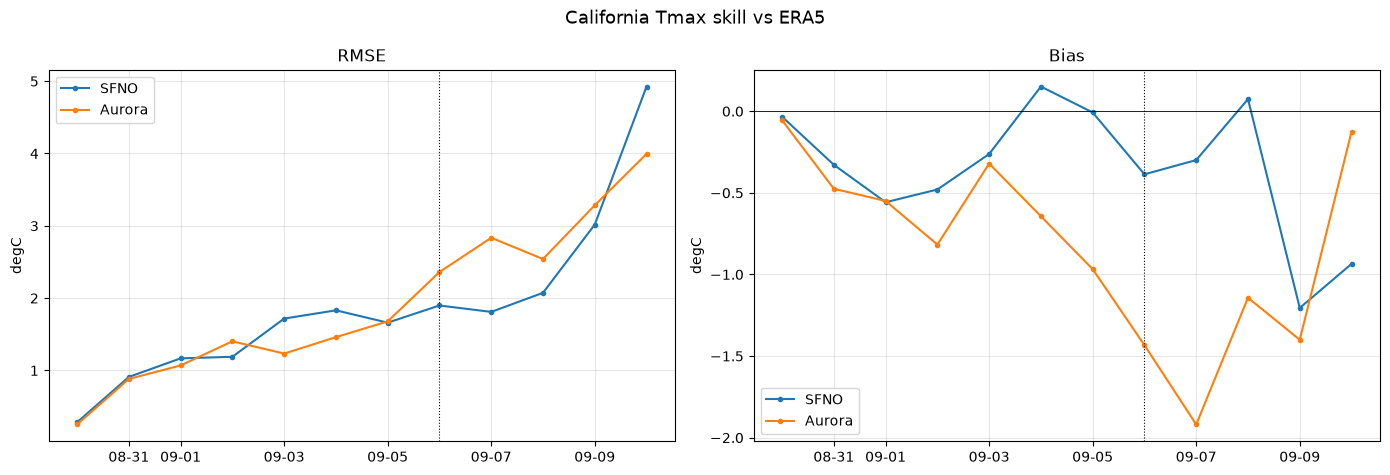

In [8]:
reg  = REGIONS["CALIFORNIA"]
e_ca = crop_bbox(era5_tmax, reg["lat"], reg["lon360"])
peak = days[np.argmin(np.abs(days - EVENT_PEAK))]

fig, (ax_r, ax_b) = plt.subplots(1, 2, figsize=(14, 4.8))
for k in MODELS:
    err = error_metrics_per_day(crop_bbox(tmax[k], reg["lat"], reg["lon360"]), e_ca)
    ax_r.plot(xdays, err["rmse"].values, marker="o", ms=3, label=MODELS[k]["label"])
    ax_b.plot(xdays, err["bias"].values, marker="o", ms=3, label=MODELS[k]["label"])
for ax, ttl in ((ax_r, "RMSE"), (ax_b, "Bias")):
    ax.axvline(xpeak, color="k", lw=0.8, ls=":")
    ax.set_title(ttl); ax.set_ylabel("degC")
    ax.grid(alpha=0.3); ax.legend(); ax.xaxis.set_major_formatter(mdates.DateFormatter("%m-%d"))
ax_b.axhline(0, color="k", lw=0.6)
fig.suptitle("California Tmax skill vs ERA5", fontsize=13)
fig.tight_layout()
fig.savefig(FIG_DIR / "skill_comparison_california.png", dpi=110, bbox_inches="tight")
plt.show()

**How to read this.** Left: the area-weighted RMSE of daily maximum temperature over California against ERA5 for each forecast day; lower is better. Right: the bias (`model − ERA5`); below zero the model is too cool, above zero too hot. The dotted vertical line marks the Sep 6 peak. Look for how quickly each curve grows with lead time and whether a model's bias keeps one sign. Both panels are measured against ERA5, a reanalysis, not against station observations.

## 6b · Consolidated skill table

The same daily-Tmax errors for all three scales in one table, saved to `docs/results/HeatWaves_metrics.csv` (the README embeds it). Bias is `model − ERA5` in °C; "peak-day" is the forecast day nearest Sep 6 and "event-mean" averages the daily values over Aug 31 – Sep 9. ERA5 is a reanalysis, so these numbers measure agreement with ERA5, not with station observations.

In [9]:
rows = []
for region in ("GLOBAL", "CONUS", "CALIFORNIA"):
    reg = REGIONS[region]
    ref = crop_bbox(era5_tmax, reg["lat"], reg["lon360"])
    for key, model in MODELS.items():
        err = error_metrics_per_day(crop_bbox(tmax[key], reg["lat"], reg["lon360"]), ref)
        at_peak = err.sel(day=peak)
        in_event = err.sel(day=slice(EVENT_START, EVENT_END)).mean("day")
        rows.append({
            "Region": "CONUS" if region == "CONUS" else region.title(),
            "Model": model["label"],
            "Peak-day bias (°C)": round(float(at_peak["bias"]), 2),
            "Peak-day RMSE (°C)": round(float(at_peak["rmse"]), 2),
            "Peak-day MAE (°C)": round(float(at_peak["mae"]), 2),
            "Event-mean bias (°C)": round(float(in_event["bias"]), 2),
            "Event-mean RMSE (°C)": round(float(in_event["rmse"]), 2),
        })
metrics_df = pd.DataFrame(rows)
metrics_df.to_csv(RESULTS_DIR / "HeatWaves_metrics.csv", index=False)
print("Daily-Tmax skill vs ERA5 (bias = model - ERA5)\n")
print(metrics_df.to_string(index=False))

Daily-Tmax skill vs ERA5 (bias = model - ERA5)

    Region  Model  Peak-day bias (°C)  Peak-day RMSE (°C)  Peak-day MAE (°C)  Event-mean bias (°C)  Event-mean RMSE (°C)
    Global   SFNO               -0.30                2.64               1.61                 -0.22                  2.17
    Global Aurora               -0.70                2.40               1.63                 -0.58                  1.90
     CONUS   SFNO               -0.17                2.45               1.76                  0.42                  2.08
     CONUS Aurora               -0.68                2.78               2.14                 -0.45                  2.31
California   SFNO               -0.39                1.90               1.48                 -0.33                  1.73
California Aurora               -1.43                2.36               1.71                 -0.97                  1.87


**How to read this.** Each row is one model at one scale. Smaller RMSE and MAE and a bias near zero are better; a negative bias means the model is cooler than ERA5. Compare the peak-day columns (a single day) with the event-mean columns (the whole window) to see whether a model's error is specific to the extreme day. Global rows are dominated by the rest of the planet, not by California.

## 7 · Per-model deep dives — model vs ERA5

One grouped figure per model so you can investigate a single model against ERA5 in isolation:
**left** = daily-Tmax time series at each city (model solid, ERA5 dashed, one color per city);
**right** = that model's California error growth (bias / RMSE / MAE vs lead). The dotted line marks Sep 6.

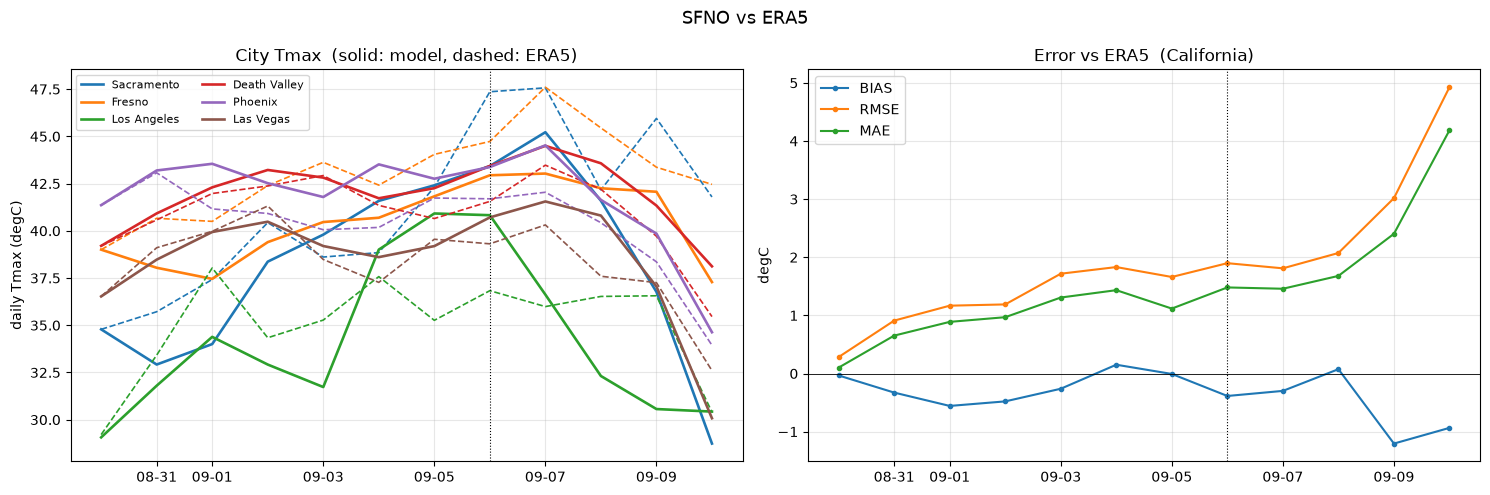

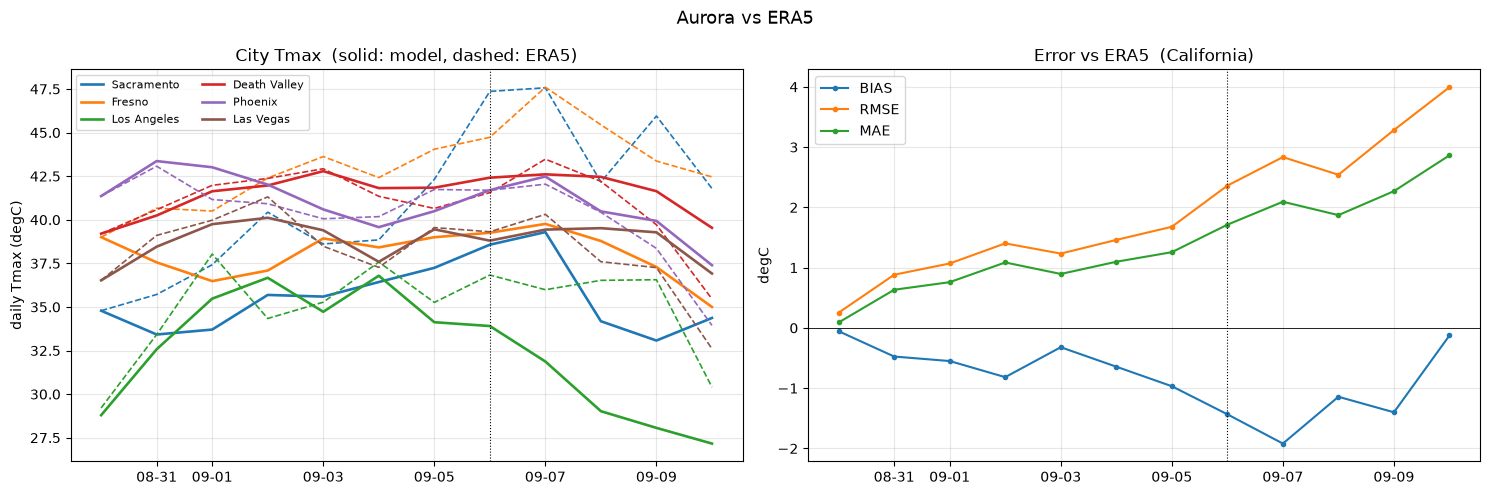

In [10]:
def city_series(daily, lat, lon):
    '''Nearest-gridpoint daily-Tmax series at a city (lon given in -180..180).'''
    return daily.sel(lat=lat, lon=lon % 360, method="nearest")

def model_vs_era5_panel(key):
    '''Grouped per-model figure: city time series (model vs ERA5) + California error growth.'''
    label  = MODELS[key]["label"]
    md, ed = tmax[key], era5_tmax
    reg    = REGIONS["CALIFORNIA"]
    err    = error_metrics_per_day(crop_bbox(md, reg["lat"], reg["lon360"]),
                                   crop_bbox(ed, reg["lat"], reg["lon360"]))

    fig, (axL, axR) = plt.subplots(1, 2, figsize=(15, 5))
    cmap = plt.get_cmap("tab10")
    for i, (city, (clat, clon)) in enumerate(CITIES.items()):
        c = cmap(i % 10)
        axL.plot(xdays, city_series(md, clat, clon).values, color=c, lw=1.9, label=city)
        axL.plot(xdays, city_series(ed, clat, clon).values, color=c, lw=1.2, ls="--")
    axL.axvline(xpeak, color="k", lw=0.8, ls=":")
    axL.set_title("City Tmax  (solid: model, dashed: ERA5)")
    axL.set_ylabel("daily Tmax (degC)"); axL.grid(alpha=0.3); axL.legend(fontsize=8, ncol=2)
    axL.xaxis.set_major_formatter(mdates.DateFormatter("%m-%d"))

    for name in ("bias", "rmse", "mae"):
        axR.plot(xdays, err[name].values, marker="o", ms=3, label=name.upper())
    axR.axhline(0, color="k", lw=0.6); axR.axvline(xpeak, color="k", lw=0.8, ls=":")
    axR.set_title("Error vs ERA5  (California)")
    axR.set_ylabel("degC"); axR.grid(alpha=0.3); axR.legend()
    axR.xaxis.set_major_formatter(mdates.DateFormatter("%m-%d"))

    fig.suptitle(f"{label} vs ERA5", fontsize=13)
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"deepdive_{key.lower()}.png", dpi=110, bbox_inches="tight")
    plt.show()

for k in MODELS:
    model_vs_era5_panel(k)

**How to read this.** Left: for each city, the model's daily Tmax (solid) against ERA5 (dashed, same color); the gap between the two lines is that city's error, and the dotted line marks Sep 6. Right: the model's California-wide error growth by forecast day (bias, RMSE and MAE in °C). Look for the day the curves start to drift away from ERA5, and for the cities (desert versus coastal) where the gap is largest.

## Summary

- **Peak-day maps (§5):** where each model puts the hottest air on Sep 6 compared with ERA5, and where the errors are largest.
- **Heat-wave day counts (§5b):** whether each model sustains runs of three or more days above 100 °F and 104 °F in the same places as ERA5.
- **Skill versus lead (§6):** how fast the daily-Tmax RMSE and bias over California grow with forecast day.
- **Consolidated skill table (§6b):** peak-day and event-mean bias, RMSE and MAE for each model at global, CONUS and California scales.
- **Per-model deep dives (§7):** city-by-city daily-Tmax series and California error growth for each model in isolation.

All errors are measured against ERA5, a reanalysis rather than station observations, and daily maxima use 6-hourly samples. The numbers change with every run, so they live in the tables above and in the CSV file `docs/results/HeatWaves_metrics.csv`, not in this text.